# [실습] 머신러닝이란 무엇인가 — 첫 모델 만들기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 1 실습. 해지 고객을 미리 찾을 수 있을까?

**필수 머신러닝 · Chapter 1**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 규칙 |
| Part 3 | 모델 만들기와 실험 기록 |
| Part 4 | 비교하고 결정하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 고객관리(CS)팀
> **목적**: 해지할 가능성이 높은 고객에게 미리 연락해 혜택을 제안하고 싶다.
> **제약**: 상담 인력이 한정되어 있어 모든 고객에게 연락할 수는 없다.
> **질문**: 해지할 고객을 미리 알 수 있을까?

## 오늘 실습의 질문

> **머신러닝 모델은 CS팀이 지금 쓰는 방법보다 얼마나 더 나은가? 그 차이는 모델을 도입할 만한 크기인가?**

이 질문에 답하려면 "지금 쓰는 방법"이 필요합니다. 그래서 여러분이 CS팀 담당자가 되어 **사람이 쓰는 규칙**을 먼저 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 겨루게 합니다. 마지막에는 CS팀에 보낼 권고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

이 실습의 목표는 정확도를 높이는 것이 아니라 **모델의 점수를 무엇과 비교해 읽을지 스스로 정하는 것**입니다. 판단 칸을 비워 두면 실습이 끝난 것이 아닙니다.

## 준비

`WA_Fn-UseC_-Telco-Customer-Churn.csv` 파일을 이 노트북과 같은 폴더에 두세요.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 세 개만 썼습니다. 여기서는 데이터 전체를 직접 살펴보고, 강의에서 일부러 뺐던 **누적 요금(TotalCharges)** 문제를 직접 해결합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** 데이터를 불러와 `df`에 저장하고, 행과 열의 수, 그리고 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 차례로 쓰면 됩니다.
</details>

In [2]:
# 여기에 코드를 작성하세요

import shutil
from datetime import datetime
from pathlib import Path

import kagglehub

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

csv_file = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
local_path = Path(csv_file)  # 현재 작업 디렉토리(상대경로) 기준

if local_path.exists():
    print(f"기존 파일 사용: {local_path}")
else:
    print("파일이 없어서 다운로드를 진행합니다...")
    cache_path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    shutil.copy(Path(cache_path) / csv_file, local_path)
    print(f"다운로드 완료: {local_path}")

# CSV 파일이 로컬에 저장된 시각 = 데이터 수집일자
# (참고) 파일 수정 시각(mtime)은 파일을 편집하거나 옮기면 바뀔 수 있음.
# 더 확실히 보존하려면 다운로드 시점에 별도 메타 파일(예: collected_at.txt)에
# 날짜를 기록해 두고 그 값을 읽어 쓰는 방식도 있음.
collected = datetime.fromtimestamp(local_path.stat().st_mtime)
print("데이터 수집 날짜:", collected.strftime("%Y-%m-%d %H:%M:%S"))

df = pd.read_csv(local_path)
print("-"*70)
print("행과 열:",df.shape)
df.head()

기존 파일 사용: WA_Fn-UseC_-Telco-Customer-Churn.csv
데이터 수집 날짜: 2019-09-27 19:30:08
----------------------------------------------------------------------
행과 열: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1-2. 해지 비율 확인하기

**[직접 작성]** 해지 여부(`Churn`)별 고객 수와 비율을 확인하세요. 강의 Part 2에서 본 숫자와 같은지 확인합니다.

<details><summary>힌트</summary>

`df["Churn"].value_counts()`는 개수를, `value_counts(normalize=True)`는 비율을 보여줍니다.
</details>

In [3]:
# 여기에 코드를 작성하세요

# churn 해지여부별 고객 수와 비율

churn_counts = df["Churn"].value_counts()
churn_ratio = df["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "고객 수" : churn_counts,
    "비율 (%)": churn_ratio.round(2)
})
churn_summary.index.name = "해지여부(Churn)"

print("전체 고객 수: ", len(df))
churn_summary

전체 고객 수:  7043


,고객 수,비율 (%)
해지여부(Churn),,
No,5174,73.46
Yes,1869,26.54


## 1-3. 열의 자료형 확인하기

**[직접 작성]** 각 열의 자료형을 확인하세요.

<details><summary>힌트</summary>

`df.info()` 또는 `df.dtypes`를 쓰세요.
</details>

In [4]:
# 여기에 코드를 작성하세요

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

> **[판단]** 월 요금(`MonthlyCharges`)과 누적 요금(`TotalCharges`)은 둘 다 금액입니다. 그런데 두 열의 자료형이 같은가요? 다르다면 무엇이 다른가요?
>
> 나의 답: 월 요금(`MonthlyCharges`)은 실수형(`float64`)이고, 누적 요금(`TotalCharges`)은 문자열(`str`)이다.

## 1-4. 누적 요금이 숫자가 아닌 이유 찾기

누적 요금 열에는 숫자로 바꿀 수 없는 값이 섞여 있습니다. `pd.to_numeric(열, errors="coerce")`는 열을 숫자로 바꾸되, 바꿀 수 없는 값은 빈 값(`NaN`)으로 만들어 줍니다.

**[직접 작성]** 아래 순서로 코드를 작성하세요.

1. 누적 요금을 숫자로 바꾼 결과를 `tc`에 저장한다
2. `tc`에서 빈 값이 몇 개인지 센다
3. 빈 값인 고객들의 `tenure`, `MonthlyCharges`, `TotalCharges`, `Churn`을 출력한다

<details><summary>힌트</summary>

빈 값 개수는 `tc.isna().sum()`, 빈 값인 행만 고르려면 `df[tc.isna()]` 또는 `df.loc[tc.isna(), [열 이름들]]`을 쓰세요.
</details>

In [5]:
# 여기에 코드를 작성하세요

# 1. 누적 요금을 숫자로 바꿔 tc에 저장
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. tc의 빈값 확인
print("tc의 빈값 개수 :",tc.isnull().sum())

# 3. 빈 값인 고객들의 "tenure", "MonthlyCharges", "TotalCharges", "Churn" 출력
df.loc[tc.isnull(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

tc의 빈값 개수 : 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [6]:
# 숫자로 변환하기 전 원본 값 확인 (tc가 NaN인 행) 
df.loc[tc.isnull(), "TotalCharges"]

488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: TotalCharges, dtype: str

In [7]:
raw = df.loc[tc.isnull(), "TotalCharges"]
print(raw.map(repr).unique())   # ["' '"]  → 따옴표 사이에 공백 1칸
print(raw.str.len().unique())   # [1]      → 길이 1짜리 문자열

<ArrowStringArray>
['' '']
Length: 1, dtype: str
[1]


> **[판단]** 빈 값인 고객들에게는 어떤 공통점이 있나요? 이 고객들의 누적 요금이 비어 있는 이유를 추측해 보세요.
>
> 나의 답: 모두 `tenure`이 0이며, `Churn`은 No이다. 원본 값이 공백 문자열이라 NaN으로 바뀐 것이고, 가입 직후라 아직 누적 요금이 기록되지 않은 신규고객으로 추정된다.

## 1-5. 빈 값 처리 방법 정하기

빈 값을 처리하는 방법은 여러 가지입니다.

| 방법 | 코드 예시 | 생각해 볼 점 |
| --- | --- | --- |
| 해당 고객 삭제 | `df = df[tc.notna()]` | 고객을 데이터에서 지워도 되는가? |
| 0으로 채우기 | `tc.fillna(0)` | 이 고객들의 실제 누적 요금은 0인가? |
| 월 요금으로 채우기 | `tc.fillna(df["MonthlyCharges"])` | 첫 달 요금이 이미 청구되었다고 볼 수 있는가? |

정답은 없습니다. 1-4에서 추측한 이유에 가장 잘 맞는 방법을 고르세요. (이 세 방법은 데이터 전체의 통계값을 쓰지 않으므로, 평가용 데이터를 나누기 전에 적용해도 괜찮습니다.)

**[직접 작성]** 고른 방법으로 `df["TotalCharges"]`를 숫자형 열로 바꾸고, 빈 값이 남지 않았는지 확인하세요.

In [8]:
# 여기에 코드를 작성하세요

# tc 활용
df["TotalCharges"] = tc.fillna(0)

# 빈 값이 남지 않았는지 확인
print("TotalCharges 빈값 개수 :", df["TotalCharges"].isnull().sum())
print("TotalCharges dtype :", df["TotalCharges"].dtype)

TotalCharges 빈값 개수 : 0
TotalCharges dtype : float64


> **[판단]** 어떤 방법을 골랐나요? 그 이유를 한 줄로 적으세요. 이 결정을 CS팀에 보고할 때 알려야 할 점이 있다면 함께 적으세요.
>
> 나의 답: 0으로 채우기 -> 11명 모두 가입기간이 한 달 미만인 신규 고객이라 아직 청구 전으로 추정했고, CS 팀에는 원래 공백 문자열이던 값을 추정에 따라 0 처리했으니 실제 청구 여부 확인이 필요함을 알린다.

## 1-6. 평가용 데이터 먼저 떼어 두기

강의 Part 2에서 배운 원칙입니다. **평가용 데이터는 모델이 학습하는 동안 보면 안 됩니다.** 이 실습에서는 규칙을 만들 때도 같은 원칙을 지킵니다. 그래서 데이터를 탐색하기 **전에** 평가용 20%를 먼저 떼어 둡니다. 이후의 탐색과 규칙 만들기는 학습용 데이터(`train_df`)만 보고 하고, 평가용 데이터(`test_df`)는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%와 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, `stratify`는 해지 여부(`Churn`)로 합니다.

<details><summary>힌트</summary>

강의 3-2의 ③과 같습니다. 다만 이번에는 `X`, `y`가 아니라 `df` 전체를 나눕니다.

`train_df, test_df = train_test_split(df, test_size=..., random_state=..., stratify=...)`
</details>

In [9]:
# 여기에 코드를 작성하세요

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Churn"])
train_rat = len(train_df)/len(df)
test_rat = len(test_df)/len(df)
print("train : test 개수 ->",len(train_df),":", len(test_df))
print("train : test 비율 ->", round(train_rat, 2),":", round(test_rat, 2) )

train : test 개수 -> 5634 : 1409
train : test 비율 -> 0.8 : 0.2


> **[판단]** 데이터를 탐색하기 전에 평가용 데이터를 먼저 떼어 두는 이유는 무엇인가요? 만약 평가용 데이터까지 보면서 규칙을 고친다면 어떤 문제가 생길까요?
>
> 나의 답: 평가용 데이터를 보고 규칙을 학습하면 답을 미리 본 셈이라 평가 점수가 부풀려져 일반화 성능을 제대로 측정할 수 없다.

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-5에서 빈 값을 0으로 채우는 한 가지 선택을 적용한 것이며, 정답이라는 뜻은 아닙니다. 1-6까지 끝낸 사람은 실행하지 않아도 됩니다.

In [10]:
# [제공] 체크포인트: 1-6까지 끝낸 사람은 실행하지 않아도 됩니다
# df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
# df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
# train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Churn"])
# print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

아래 셀은 이후 Part에서 쓰는 도구를 만듭니다. 읽어 보고 실행하세요.

| 도구 | 하는 일 |
| --- | --- |
| `churn_rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 해지율을 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate(이름, 예측)` | 평가용 데이터에서 정확도와, 해지 고객을 몇 명 찾았는지 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(...)` | 실험 결과를 기록표에 한 줄 추가한다 |

In [11]:
# [제공] 실습 도구
y_test = test_df["Churn"]

def churn_rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 해지율을 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    return train_df.groupby(key, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

def evaluate(name, pred):
    """평가용 데이터에서 예측(Yes/No)을 채점합니다. 정확도를 돌려줍니다."""
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    acc = (pred == y_test).mean()
    flagged = (pred == "Yes").sum()
    found = ((pred == "Yes") & (y_test == "Yes")).sum()
    total = (y_test == "Yes").sum()
    print(f"[{name}] 정확도 {acc:.3f} | 해지로 예측 {flagged}명 중 실제 해지 {found}명 | 전체 해지 고객 {total}명 중 {found}명을 찾음")
    return acc

def make_data(features):
    """피처 목록을 받아 학습용·평가용 X, y를 만듭니다. 평가용 고객은 항상 같습니다."""
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["Churn"], test_df["Churn"]

experiment_log = []
def record(name, features, depth, accuracy):
    """실험 결과를 기록표에 한 줄 추가합니다."""
    experiment_log.append({
        "실험": name,
        "피처": ", ".join(features) if features else "-",
        "깊이": depth,
        "평가용 정확도": round(float(accuracy), 3),
    })
    print(f"기록: [{name}] {accuracy:.3f}")

## 1-7. 해지와 관련 있어 보이는 정보 찾기

이제 학습용 데이터에서 "어떤 고객이 많이 해지하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다.

전체 평균 해지율은 약 26.5%입니다. 이보다 **눈에 띄게 높은** 집단을 찾는 것이 목표입니다.

**[직접 작성]** `churn_rate_by`로 계약 유형(`Contract`)별 해지율을 확인하세요.

In [12]:
# 여기에 코드를 작성하세요

churn_rate_by("Contract")

Contract
Month-to-month    0.427
One year          0.111
Two year          0.029
Name: Churn, dtype: float64

**[직접 작성]** 다른 열도 같은 방법으로 살펴보세요. **세 개 이상**의 열을 골라 해지율을 확인합니다. 숫자 열(`tenure`)은 구간을 나눠야 합니다.

<details><summary>힌트</summary>

열 이름 목록은 `df.columns.tolist()`로 볼 수 있습니다. 한 줄에 하나씩 `print(churn_rate_by("열 이름"))`을 쓰세요.

가입 기간처럼 숫자 열은 구간 경계를 함께 줍니다.

`churn_rate_by("tenure", bins=[-1, 6, 12, 24, 48, 72])`
</details>

In [13]:
# 여기에 코드를 작성하세요
cat_cols = [
    c for c in train_df.select_dtypes(exclude="number").columns
    if c not in ["customerID", "Churn"]
]

for col in cat_cols:
    print(f"■ {col}")
    print(churn_rate_by(col))
    print("-" * 40)

■ gender
gender
Female    0.266
Male      0.264
Name: Churn, dtype: float64
----------------------------------------
■ Partner
Partner
No     0.328
Yes    0.199
Name: Churn, dtype: float64
----------------------------------------
■ Dependents
Dependents
No     0.314
Yes    0.152
Name: Churn, dtype: float64
----------------------------------------
■ PhoneService
PhoneService
No     0.242
Yes    0.268
Name: Churn, dtype: float64
----------------------------------------
■ MultipleLines
MultipleLines
No                  0.250
No phone service    0.242
Yes                 0.288
Name: Churn, dtype: float64
----------------------------------------
■ InternetService
InternetService
DSL            0.187
Fiber optic    0.421
No             0.072
Name: Churn, dtype: float64
----------------------------------------
■ OnlineSecurity
OnlineSecurity
No                     0.419
No internet service    0.072
Yes                    0.144
Name: Churn, dtype: float64
--------------------------------------

In [14]:
rows = []
for col in cat_cols:
    s = churn_rate_by(col)
    for value, rate in s.items():
        rows.append({"열": col, "값": value, "해지율": rate})

summary = pd.DataFrame(rows).sort_values("해지율", ascending=False)
summary.head(15)   # 해지율 높은 상위 15개 집단

,열,값,해지율
39,PaymentMethod,Electronic check,0.457
32,Contract,Month-to-month,0.427
12,InternetService,Fiber optic,0.421
14,OnlineSecurity,No,0.419
23,TechSupport,No,0.418
17,OnlineBackup,No,0.401
20,DeviceProtection,No,0.390
36,PaperlessBilling,Yes,0.338
29,StreamingMovies,No,0.336
26,StreamingTV,No,0.331


In [15]:
# SeniorCitizen은 0/1이라 구간 없이 바로
print(churn_rate_by("SeniorCitizen"))

# 연속형은 구간 나눠서
print(churn_rate_by("tenure", bins=[-1, 12, 24, 48, 72]))
print(churn_rate_by("MonthlyCharges", bins=[0, 35, 70, 120]))
print(churn_rate_by("TotalCharges", bins=[-1, 500, 2000, 4000, 9000]))

SeniorCitizen
0    0.237
1    0.411
Name: Churn, dtype: float64
tenure
(-1, 12]    0.473
(12, 24]    0.286
(24, 48]    0.202
(48, 72]    0.099
Name: Churn, dtype: float64
MonthlyCharges
(0, 35]      0.106
(35, 70]     0.238
(70, 120]    0.355
Name: Churn, dtype: float64
TotalCharges
(-1, 500]       0.404
(500, 2000]     0.240
(2000, 4000]    0.235
(4000, 9000]    0.154
Name: Churn, dtype: float64


**[제공]** 해지 여부에 따라 가입 기간(`tenure`) 분포가 어떻게 다른지 그려 봅니다.

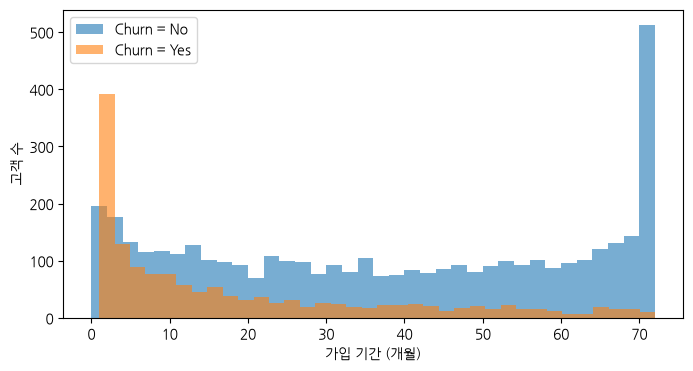

In [16]:
# [제공] 해지 여부별 가입 기간 분포 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
for label in ["No", "Yes"]:
    ax.hist(train_df.loc[train_df["Churn"] == label, "tenure"], bins=36, alpha=0.6, label=f"Churn = {label}")
ax.set_xlabel("가입 기간 (개월)")
ax.set_ylabel("고객 수")
ax.legend()
plt.show()

> **[판단]** 해지율이 전체 평균보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 해지율이 △△%")
>
> 나의 답: 가입기간(`tenure`)이 12개월 이하인 고객의 해지율이 47.3%(평균 대비 약 1.8배), 전자수표(`Electronic check`)로 결제하는 고객의 해지율이 45.7%(평균 대비 약 1.7배)이다.
>
> 그 밖에도 평균(약 26.5%)보다 해지율이 높은 집단은 다음과 같다.
>
> | 집단 | 해지율 | 평균 대비 |
> |---|---|---|
> | 월 단위 계약 (`Contract = Month-to-month`) | 42.7% | 약 1.6배 |
> | 광섬유 인터넷 (`InternetService = Fiber optic`) | 42.1% | 약 1.6배 |
> | 보안 서비스 미사용 (`OnlineSecurity = No`) | 41.9% | 약 1.6배 |
> | 기술지원 미사용 (`TechSupport = No`) | 41.8% | 약 1.6배 |
> | 고령자 (`SeniorCitizen = 1`) | 41.1% | 약 1.6배 |
> | 누적 요금 500 이하 (`TotalCharges`) | 40.4% | 약 1.5배 |
> | 월 요금 70 초과 (`MonthlyCharges`) | 35.5% | 약 1.3배 |

> **[판단]** 이 집계만 보고 "그 조건을 바꾸게 하면 해지가 줄어든다"고 말할 수 있을까요? 강의 3-4의 세 번째 항목을 떠올려 보세요.
>
> 나의 답: 말할 수 없다. 집계는 상관관계만 보여 줄 뿐 인과는 증명하지 못한다. 월 단위 계약 고객은 원래 해지 성향이 높은 사람들일 수 있어서, 계약을 바꾸게 해도 해지가 줄어든다는 보장이 없다. 확인하려면 A/B 테스트가 필요하다.

---
# Part 2. 현행 방법 만들기: 사람이 쓰는 규칙

여러분이 CS팀 담당자라고 생각해 보세요. 머신러닝 없이, 오늘 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 2-4에서 본 세 번째 베이스라인, "현행 규칙"입니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.** 현업에서 실제로 쓸 수 있을 만큼 단순해야 합니다.
- 근거는 **1-7에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객은 해지 위험(Yes), 아니면 No"로 답합니다.

## 2-1. 베이스라인 계산

먼저 비교 기준을 만듭니다. 모든 고객에게 "No"라고 답하는 방법의 성적입니다.

**[직접 작성]** 평가용 고객 전원에게 "No"라고 답하는 예측을 만들어 `evaluate`로 채점하고, 정확도를 `baseline_acc`에 저장하세요.

<details><summary>힌트</summary>

`baseline_pred = pd.Series("No", index=test_df.index)`로 예측을 만들고, `baseline_acc = evaluate("전부 No", baseline_pred)`로 채점합니다.
</details>

In [17]:
# 여기에 코드를 작성하세요
# 평가용 고객 전원에게 "No"라고 답하는 예측
pred_all_no = ["No"] * len(test_df)

# evaluate로 채점하고 정확도를 baseline_acc에 저장
baseline_acc = evaluate("전원 No (베이스라인)", pred_all_no)


[전원 No (베이스라인)] 정확도 0.735 | 해지로 예측 0명 중 실제 해지 0명 | 전체 해지 고객 374명 중 0명을 찾음


## 2-2. 나의 규칙 만들기

먼저 말로 적고, 그다음 코드로 옮깁니다.

> **[판단]** 나의 규칙(말로): 만약 전자수표로 결제하고 가입 12개월 이하이면 해지 위험으로 본다.
>
> 이 조건을 고른 근거(1-7의 어떤 집계인가): 결제 방식별 해지율(`PaymentMethod`)에서 전자수표가 45.7%, 가입 기간 구간별 해지율(`tenure`)에서 12개월 이하가 47.3%로, 둘 다 평균(약 26.5%)보다 눈에 띄게 높았다.
>
> 나의 답: 두 조건을 함께 만족하는 고객은 학습용 데이터에서 778명, 해지율 62.6%로 평균의 약 2.4배였다. 대상 인원이 많은 규칙보다 해지율이 높은 쪽을 택했고, 대신 해지 고객 일부만 찾는다는 한계가 있다. 이 규칙은 해지를 단정하는 것이 아니라 CS팀이 먼저 연락할 대상을 좁히는 기준이다.

In [18]:
def cond_summary(name, cond):
    n = cond.sum()
    churned = (train_df.loc[cond, "Churn"] == "Yes").sum()
    print(f"{name}: {n}명, 해지율 {churned / n:.3f}, 이 집단의 해지 고객 {churned}명")

cond_ec = train_df["PaymentMethod"] == "Electronic check"
cond_mtm = train_df["Contract"] == "Month-to-month"
cond_new = train_df["tenure"] <= 12

cond_summary("전자수표", cond_ec)
cond_summary("월 단위 계약", cond_mtm)
cond_summary("가입 12개월 이하", cond_new)
cond_summary("월 단위 & 12개월 이하", cond_mtm & cond_new)
cond_summary("전자수표 & 월 단위", cond_ec & cond_mtm)
cond_summary("전자수표 & 12개월 이하", cond_ec & cond_new)

전자수표: 1891명, 해지율 0.457, 이 집단의 해지 고객 865명
월 단위 계약: 3102명, 해지율 0.427, 이 집단의 해지 고객 1326명
가입 12개월 이하: 1737명, 해지율 0.473, 이 집단의 해지 고객 822명
월 단위 & 12개월 이하: 1594명, 해지율 0.511, 이 집단의 해지 고객 814명
전자수표 & 월 단위: 1484명, 해지율 0.542, 이 집단의 해지 고객 805명
전자수표 & 12개월 이하: 778명, 해지율 0.626, 이 집단의 해지 고객 487명


**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객에게 적용하고, 예측을 `rule_pred`에 저장하세요. 그다음 `evaluate`로 채점해 정확도를 `rule_acc`에 저장합니다.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다. 예를 들어 "인터넷이 광케이블이고 월 요금이 80 이상"이라면

```python
condition = (test_df["InternetService"] == "Fiber optic") & (test_df["MonthlyCharges"] >= 80)
rule_pred = pd.Series(np.where(condition, "Yes", "No"), index=test_df.index)
rule_acc = evaluate("내 규칙", rule_pred)
```

이 예시는 형식만 보여주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [19]:
# 여기에 코드를 작성하세요
# 예측은 rule_pred, 정확도는 rule_acc라는 이름으로 저장하세요 (Part 3, 4에서 다시 씁니다)

# 규칙: 전자수표로 결제하고 가입 12개월 이하이면 해지 위험(Yes)
condition = (test_df["PaymentMethod"] == "Electronic check") & (test_df["tenure"] <= 12)
rule_pred = pd.Series(np.where(condition, "Yes", "No"), index=test_df.index)

# 채점하고 정확도를 rule_acc에 저장
rule_acc = evaluate("내 규칙 (전자수표 & 12개월 이하)", rule_pred)

[내 규칙 (전자수표 & 12개월 이하)] 정확도 0.762 | 해지로 예측 200명 중 실제 해지 119명 | 전체 해지 고객 374명 중 119명을 찾음


> **[판단]** 내 규칙은 "전부 No"보다 정확도가 높은가요? 두 방법이 찾아낸 해지 고객 수도 비교해 보세요.
>
> 나의 답: 전부 No의 정확도는 0.735, 내 규칙의 정확도는 0.762로 약간 더 높다. 찾아낸 해지 고객은 전부 No가 374명 중 0명, 내 규칙은 374명 중 119명(약 32%)이다. 정확도도 소폭 높고, 해지 고객을 실제로 찾아낸다는 점에서 내 규칙이 더 의미 있다. 다만 해지로 예측한 200명 중 119명(약 60%)만 실제 해지였고, 전체 해지 고객의 약 68%는 놓쳤다.

> **[판단]** 정확도는 비슷한데 찾아낸 해지 고객 수가 크게 다른 두 방법이 있다면, CS팀에는 어느 쪽이 더 쓸모 있을까요? 이유를 적어 보세요.
>
> 나의 답: 해지 고객을 더 많이 찾아낸 쪽이 더 쓸모 있다. CS팀의 목적은 해지할 고객에게 미리 연락하는 것인데, 정확도가 비슷해도 해지 고객을 거의 못 찾는 방법은 연락할 대상을 알려 주지 못하기 때문이다. 실제로 전부 No(0.735)와 내 규칙(0.762)은 정확도 차이가 작지만, 찾은 해지 고객은 0명과 119명으로 크게 다르다. 다만 많이 찾는 대신 엉뚱한 사람에게 연락하는 비율(내 규칙은 200명 중 81명)도 함께 봐야 불필요한 연락을 줄일 수 있다.

---
# Part 3. 모델 만들기와 실험 기록

이제 모델을 만들어 내 규칙과 겨룹니다. 강의 Part 3의 코드를 보지 말고 먼저 직접 써 보세요. 막히면 강의 3-2를 참고해도 됩니다.

## 3-1. 첫 모델 만들기

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(["tenure", "MonthlyCharges", "Contract"])`로 `X_train, X_test, y_train, y_test`를 만든다
2. 깊이 2 결정트리(`max_depth=2`, `random_state=42`)를 학습한다
3. 평가용 데이터의 예측을 `evaluate`로 채점해 정확도를 `tree_acc`에 저장한다

<details><summary>힌트</summary>

강의 3-2의 ⑤와 같은 순서입니다. 채점은 `tree_acc = evaluate("트리(깊이 2)", model.predict(X_test))`로 합니다.
</details>

In [20]:
from sklearn.tree import DecisionTreeClassifier

# 1. 데이터 만들기
X_train, X_test, y_train, y_test = make_data(["tenure", "MonthlyCharges", "Contract"])

# 2. 깊이 2 결정트리 학습
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

# 3. 평가용 예측을 채점하고 정확도를 tree_acc에 저장
tree_acc = evaluate("트리(깊이 2)", model.predict(X_test))

[트리(깊이 2)] 정확도 0.740 | 해지로 예측 441명 중 실제 해지 224명 | 전체 해지 고객 374명 중 224명을 찾음


## 3-2. 실험 기록표 시작하기

피처와 깊이를 바꿔 가며 여러 번 실험하면, 어떤 조건에서 몇 점이 나왔는지 금방 헷갈립니다. 그래서 실험마다 한 줄씩 기록을 남깁니다. 이 습관은 이후 Chapter에서도 계속 씁니다.

**[직접 작성]** 지금까지의 결과 세 가지(전부 No, 내 규칙, 깊이 2 트리)를 `record`로 기록하세요. 베이스라인과 규칙은 피처에 `[]`, 깊이에 `"-"`를 넣으면 됩니다.

<details><summary>힌트</summary>

`record("실험 이름", 피처 목록, 깊이, 정확도)` 형태입니다.
</details>

In [21]:
record("전부 No", [], "-", baseline_acc)
record("내 규칙", [], "-", rule_acc)
record("트리(깊이 2)", ["tenure", "MonthlyCharges", "Contract"], 2, tree_acc)

기록: [전부 No] 0.735
기록: [내 규칙] 0.762
기록: [트리(깊이 2)] 0.740


## 3-3. 피처와 깊이를 바꿔 보기

**[직접 작성]** 피처를 추가하거나 깊이를 바꿔 가며 **세 번 이상** 실험하세요. 매번 `evaluate`로 채점하고 `record`로 기록합니다.

실험하기 전에, 피처를 고를 때 하나 확인할 것이 있습니다.

> **[판단]** 누적 요금(`TotalCharges`)을 피처로 쓰기 전에 생각해 보세요. 이 값은 "언제 찍힌 사진"일까요? 해지한 고객의 누적 요금은 해지 시점에서 멈춰 있지 않을까요? 이 피처를 쓸지 말지, 이유와 함께 적으세요. (정답은 Chapter 4에서 다시 확인합니다.)
>
> 나의 답: 쓰지 않는다. 누적 요금은 데이터를 뽑은 시점에 찍힌 값이라, 이미 해지한 고객은 해지 시점에서 멈춰 있어 해지 결과가 반영된 정보일 수 있다. 또 `tenure × MonthlyCharges`와 비슷한 값이라 이미 쓰는 피처와 겹친다. 그래서 일단 빼고 실험하고, Chapter 4에서 확인한다.

<details><summary>힌트</summary>

한 번의 실험은 다음 네 줄입니다.

```python
features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
acc = evaluate("인터넷 추가, 깊이 3", m.predict(X_te))
record("인터넷 추가, 깊이 3", features, 3, acc)
```

깊이는 2~5 사이에서 바꿔 보세요. 더 깊게 하면 어떻게 되는지는 강의 3-5의 표에서 이미 봤습니다.
</details>

In [22]:
# 실험 1
depth = 3
features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_tr, y_tr)
acc = evaluate(f"인터넷 추가, 깊이 {depth}", m.predict(X_te))
record(f"인터넷 추가, 깊이 {depth}", features, depth, acc)

# 실험 2
depth = 4
features = ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_tr, y_tr)
acc = evaluate(f"결제 방식 추가, 깊이 {depth}", m.predict(X_te))
record(f"결제 방식 추가, 깊이 {depth}", features, depth, acc)

# 실험 3
depth = 5
features = ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_tr, y_tr)
acc = evaluate(f"보안·지원 추가, 깊이 {depth}", m.predict(X_te))
record(f"보안·지원 추가, 깊이 {depth}", features, depth, acc)

[인터넷 추가, 깊이 3] 정확도 0.782 | 해지로 예측 197명 중 실제 해지 132명 | 전체 해지 고객 374명 중 132명을 찾음
기록: [인터넷 추가, 깊이 3] 0.782
[결제 방식 추가, 깊이 4] 정확도 0.793 | 해지로 예측 271명 중 실제 해지 177명 | 전체 해지 고객 374명 중 177명을 찾음
기록: [결제 방식 추가, 깊이 4] 0.793
[보안·지원 추가, 깊이 5] 정확도 0.794 | 해지로 예측 368명 중 실제 해지 226명 | 전체 해지 고객 374명 중 226명을 찾음
기록: [보안·지원 추가, 깊이 5] 0.794


**[제공]** 실험 기록표를 정확도 순으로 봅니다.

In [23]:
# [제공] 실험 기록표 보기
pd.DataFrame(experiment_log).sort_values("평가용 정확도", ascending=False, kind="stable")


,실험,피처,깊이,평가용 정확도
5,"보안·지원 추가, 깊이 5","tenure, MonthlyCharges, Contract, InternetServ...",5,0.794
4,"결제 방식 추가, 깊이 4","tenure, MonthlyCharges, Contract, InternetServ...",4,0.793
3,"인터넷 추가, 깊이 3","tenure, MonthlyCharges, Contract, InternetService",3,0.782
1,내 규칙,-,-,0.762
2,트리(깊이 2),"tenure, MonthlyCharges, Contract",2,0.740
0,전부 No,-,-,0.735


> **[판단]** 가장 좋은 모델은 "전부 No"보다 몇 %p 나은가요? 내 규칙보다는 몇 %p 나은가요?
>
> 나의 답: 가장 좋은 모델(보안·지원 추가, 깊이 5)의 정확도는 0.794로, "전부 No"(0.735)보다 약 5.9%p, 내 규칙(0.762)보다 약 3.2%p 높다.

> **[판단]** 가장 좋은 모델이 해지 고객을 몇 명 찾아냈나요? 내 규칙이 찾아낸 수와 비교해 보세요.
>
> 나의 답: 가장 좋은 모델은 해지 고객 374명 중 226명(약 60%)을 찾아냈고, 내 규칙은 119명(약 32%)을 찾아냈다. 모델이 107명, 약 1.9배 더 많이 찾았다. 다만 모델은 368명을 해지로 예측해 그중 142명은 실제로 해지하지 않았고(내 규칙은 200명 중 81명), 연락 대상이 늘어난 만큼 헛걸음도 늘었다.

## 3-4. 가장 나은 모델의 규칙 읽기

**[직접 작성]** 기록표에서 가장 나은 실험을 골라 그 모델을 다시 학습하고, `plot_tree`로 그리세요.

<details><summary>힌트</summary>

강의 3-3의 ⑦을 참고하세요. 깊이 3 트리는 글자가 작아지므로 `plt.figure(figsize=(20, 8))`처럼 그림을 크게 하세요.
</details>

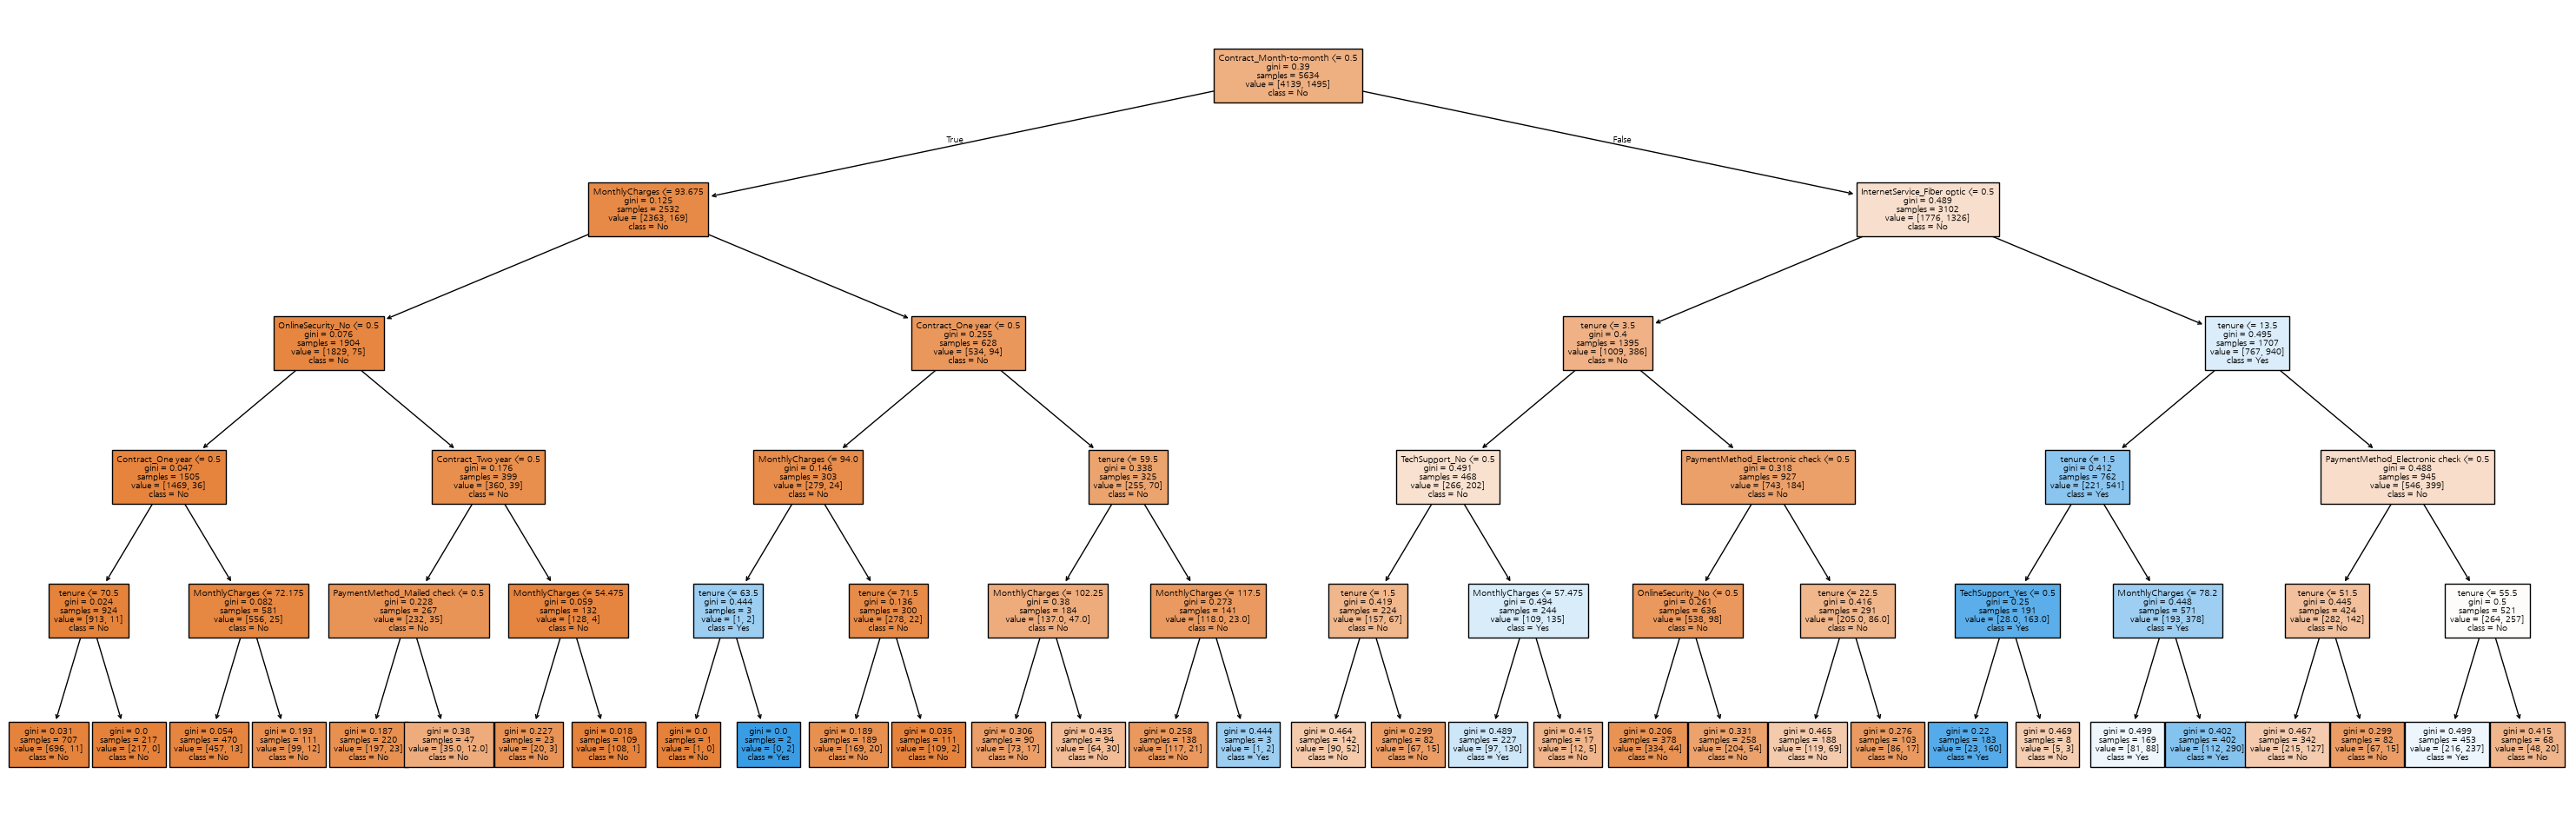

In [24]:
# 기록표 1등 : 실험 3
depth = 5
features = ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport"]
X_tr, X_te, y_tr, y_te = make_data(features)
best_model = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_tr, y_tr)

# 트리 그리기
plt.figure(figsize=(38, 12))
plot_tree(best_model, feature_names=X_tr.columns, class_names=best_model.classes_,
          filled=True, fontsize=7)
plt.show()

> **[판단]** "Yes"로 예측하는 잎을 하나 골라, 그 잎에 도착하는 고객의 조건을 말로 풀어 쓰세요. 그 잎의 고객 중 실제 해지 비율은 얼마인가요? (`value`로 계산)
>
> 나의 답: 월 단위 계약이고, 광섬유 인터넷을 쓰며, 가입 1개월 이하(`tenure <= 1.5`)이고, 기술지원을 쓰지 않는 고객이 도착하는 잎이다. 이 잎에는 183명이 도착했고 value는 [No 23, Yes 160]이므로 실제 해지 비율은 160 ÷ 183 ≈ 87.4%이다. 전체 평균 해지율(약 26.5%)의 3배가 넘는다.

In [25]:
tree = best_model.tree_

# 잎 노드만 골라서 No/Yes 명수와 해지 비율 계산
rows = []
for node in range(tree.node_count):
    if tree.children_left[node] == -1:               # 잎 노드
        counts = tree.value[node][0]                 # 버전에 따라 비율일 수 있음
        no, yes = counts * tree.n_node_samples[node] / counts.sum()
        rows.append({"node": node, "고객수": int(tree.n_node_samples[node]),
                     "No": round(no), "Yes": round(yes), "해지비율": round(yes / (no + yes), 3)})

leaf_table = pd.DataFrame(rows)

# 183명짜리 잎 확인
leaf_table[leaf_table["고객수"] == 183]

,node,고객수,No,Yes,해지비율
24,51,183,23,160,0.874


---
# Part 4. 비교하고 결정하기

이제 질문으로 돌아옵니다. **모델은 CS팀이 지금 쓰는 방법(내 규칙)보다 얼마나 나은가? 그 차이는 도입할 만한 크기인가?**

## 4-1. 예상 걸기

곧 다른 수강생들의 규칙과 모델 점수를 한 표에서 함께 봅니다. 표를 열기 **전에** 먼저 예상을 적어 두세요. 틀려도 괜찮습니다. 예상이 빗나간 지점이 오늘 가장 많이 배우는 곳입니다.

> **[판단]** 예상 ① 교실 전체에서 "모델이 규칙을 이긴 사람"은 몇 %일까요? (대략의 비율로)
>
> 나의 답: 약 80%. 내 규칙(0.762)은 모델(0.794)보다 낮았고, 조건이 세 개 이하인 규칙으로는 모델 점수를 넘기기 어렵다고 본다. 다만 규칙을 잘 고르거나 모델을 덜 다듬은 사람은 규칙이 이길 수도 있어서 100%까지는 아니라고 생각한다.

> **[판단]** 예상 ② 교실에서 가장 높은 규칙 정확도는 어느 정도일까요? 그 규칙은 조건이 많을까요, 적을까요?
>
> 나의 답: 약 0.78 정도. 조건이 2~3개로 적은 규칙일 것 같다. 약속상 조건이 세 개를 넘을 수 없고, 해지율이 높은 집단을 잘 고르면 단순해도 모델과 가까운 점수가 나올 것 같다.

## 4-2. 공유용 한 줄 만들기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. (예: `"월 단위 계약이면서 가입 12개월 이하"`)

In [26]:
my_rule_text = "전자수표로 결제하면서 가입 12개월 이하"

**[제공]** 공유 표에 붙여 넣을 한 줄과, 내 실험 기록표를 출력합니다.

In [27]:
# [제공] 공유용 한 줄 + 실험 기록표
log = pd.DataFrame(experiment_log)
models = log[~log["실험"].isin(["전부 No", "내 규칙"])]
best_row = models.sort_values("평가용 정확도", ascending=False, kind="stable").iloc[0]

print("공유 표에 붙여 넣으세요:")
print(f"규칙: {my_rule_text} | 규칙 정확도 {rule_acc:.3f} | 최고 모델 {best_row['실험']} {best_row['평가용 정확도']:.3f}")
print()
log.sort_values("평가용 정확도", ascending=False, kind="stable")

공유 표에 붙여 넣으세요:
규칙: 전자수표로 결제하면서 가입 12개월 이하 | 규칙 정확도 0.762 | 최고 모델 보안·지원 추가, 깊이 5 0.794



,실험,피처,깊이,평가용 정확도
5,"보안·지원 추가, 깊이 5","tenure, MonthlyCharges, Contract, InternetServ...",5,0.794
4,"결제 방식 추가, 깊이 4","tenure, MonthlyCharges, Contract, InternetServ...",4,0.793
3,"인터넷 추가, 깊이 3","tenure, MonthlyCharges, Contract, InternetService",3,0.782
1,내 규칙,-,-,0.762
2,트리(깊이 2),"tenure, MonthlyCharges, Contract",2,0.740
0,전부 No,-,-,0.735


## 4-3. 공유 표를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답:

> **[판단]** 조건이 적고 단순한 규칙과 조건이 많은 규칙 중, 모델과 더 비슷한 점수를 낸 것은 어느 쪽이었나요?
>
> 나의 답:

> **[판단]** 모델이 규칙을 몇 %p 이긴다면 CS팀은 모델을 도입해야 할까요? 규칙은 누구나 이해하고 내일부터 쓸 수 있지만 모델은 그렇지 않다는 점도 함께 생각해 보세요.
>
> 나의 답:

## 4-4. CS팀 권고 메모

분석 결과를 CS팀 팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **무엇을 예측했는가** (누가, 어떤 정보로, 무엇을)
2. **지금 쓰는 방법(내 규칙)과 비교해 얼마나 나은가** (정확도와, 찾아낸 해지 고객 수 모두)
3. **권고**: 모델 도입 / 규칙 유지 / 보류 중 하나를 고르고, 이유를 쓴다
4. **주의할 점**: 1-5의 빈 값 처리 결정, 타깃 정의의 한계(강의 2-1), 아직 확인하지 못한 것

> **[판단]** CS팀 권고 메모:
>
> 1. 예측한 것:
>
> 2. 현행 방법과의 비교:
>
> 3. 권고와 이유:
>
> 4. 주의할 점:
>
> 나의 답:

---
# 마무리

## 이 Chapter의 판단 포인트

> **정확도 74%는 좋은 숫자인가? 베이스라인을 보기 전까지는 알 수 없다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 첫 줄을 내 말로 적으세요.

예: "모델 점수를 보면 '전부 No'와 현행 규칙의 점수를 먼저 찾는다."

> **[판단]** 나의 체크리스트 1번:
>
> 나의 답:

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)
- 4-2에서 만든 공유용 한 줄

수고했습니다. 다음 Chapter 2에서는 숫자를 예측하는 **회귀**를 배웁니다.